# __Reproducing the Orientation Tuning Model from Ben-Yishai et al. (1995)__ 

This notebook implements and reproduces the key results of __"Theory of Orientation Tuning in Visual Cortex"__ (Ben-Yishai, Lev Bar-Or, Sompolinsky, 1995).

The paper proposes a recurrent ring model of V1 orientation selectivity, showing how sharp curve arises from cortical interaction rather than just feedforward input alone.

Below I have replicated main figures of the paper using discretized firing-rate model

## Mathematical Model

The firing rate evolves according to: 
$$
\tau \frac{dr(\theta,t)}{dt}
= -r(\theta,t)
+ F\!\left(
    I(\theta)
    + \int J(\theta - \theta')\, r(\theta')\, d\theta'
  \right)
$$



External Input:
$$ I(\theta) = I_0 + I_2\cos(2\theta) $$

Recurrent Kernel:
$$ J(\Delta\theta) = J_0 + J_2\cos(2\Delta\theta) $$

Activation Funcition:
$$ F(x) = max(0,x) $$


_External Input Tuning_

The feedforward input is modeled as:

$$ I(\theta)
= (\varepsilon c + J_2m_2)  \cos(2\theta) + c(1 - \varepsilon) - J_0m_0
\tag{5}
$$

Here:  
- c  is the stimulus contrast  
- ɛ controls the strength of orientation tuning
- J_2 is the anisotropic interaction strength
- J_1 is the isotropic interaction strength
- m_2 and m_0 are the Fourier coefficients


### Fig 1A - Hubel-Weisel Feedforward Scenario
__Purpose:__
This figure shows tuning predicted by the thalamocortical feedforward input only (no recurrent sharpening).
The tuning is broad, weak and cannot explain expermentally observed sharp selectivity.

__Key Observation:__
Even changing the parameters does not change the weak tuning, matching the argument in original paper

In [46]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import brentq 

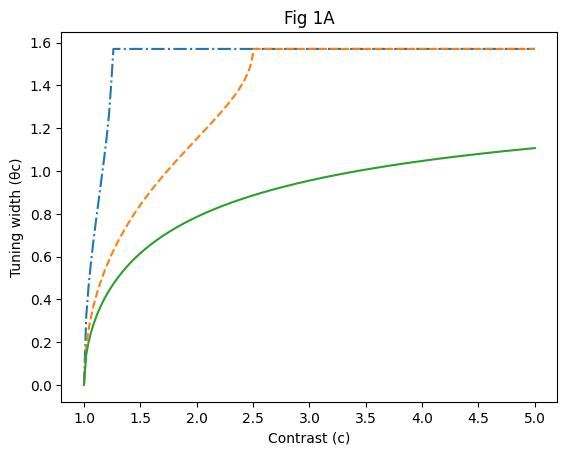

In [47]:
def theta_hw(eps, c):
    A = (1 - c*(1-eps)) / (eps*c)
    A = np.clip(A, -1, 1) 
    return 0.5*np.arccos(A)    

eps_array = np.array([0.1,0.3,0.5])
c_array = np.linspace(1.0,5.0,200)
theta_c =[]
styles = ['-.','--','-']

for eps,style in zip(eps_array, styles):
    theta_c = [theta_hw(eps, c) for c in c_array]
    plt.plot(c_array, theta_c, style)
    plt.ylabel("Tuning width (θc)")
    plt.xlabel("Contrast (c)")
    plt.title("Fig 1A")

### Fig 1B - Input-Output Gain under different inhibition regimes 
__Purpose:__
The paper contrasts two regimes:
- Uniform Inhibition : stable, weak sharpening
- Marginal Phase : network is close to instability, enabling strong inhibtion
   
__Key Observation:__
The marginal phase produces stronger responses and a nonlinear transition, matching the paper’s claim that cortical interactions sharpen tuning.

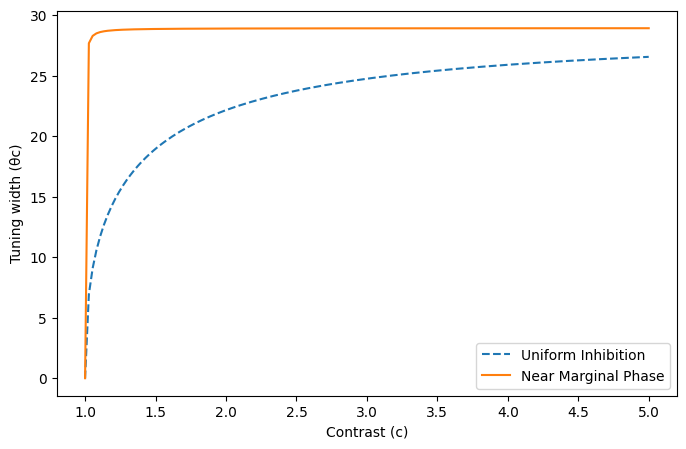

In [48]:
beta = 0.1
def A(theta):
    return (beta/np.pi)*(theta - 0.25*np.sin(4*theta))

def B(theta):
    return (beta/np.pi)*(np.sin(2*theta) - 2*theta*np.cos(2*theta))

def m2_theta(theta,c, eps, J2):
    a = A(theta)
    denom = 1 - A(theta)*J2
    if denom <= 1e-9:
        return np.sign(a*c)*1e9
    return (a*eps*c)/ denom

def m0_theta(theta, c, eps, J0, J2):
    m2 = m2_theta(theta, c, eps, J2)
    return B(theta)*(eps*c + J2*m2)


def F_theta(theta, c, eps, J0, J2):
    m2 = m2_theta(theta, c, eps, J2)
    m0 = m0_theta(theta, c, eps, J0, J2)
    return (eps*c + J2*m2) * np.cos(2*theta) + c*(1 - eps) - J0*m0 - 1.0

def theta_c_for_contrast(c, eps, J0, J2):
    left, right = 1e-6, 0.5*np.pi - 1e-6
    try:
        root = brentq(F_theta , left, right, args=(c, eps, J0, J2), maxiter = 200)
        return root
    except:
        return 0.0

cs = np.linspace(1.0,5.0,150)
eps_d, J0_d, J2_d = 0.5,155.0,0.0
theta_d = np.array([theta_c_for_contrast(c, eps_d, J0_d, J2_d) for c in cs])

eps_s, J0_s, J2_s = 0.01,86.0,112.0
theta_s = np.array([theta_c_for_contrast(c, eps_s, J0_s, J2_s) for c in cs])

theta_d_deg = theta_d * 180/np.pi
theta_s_deg = theta_s * 180/np.pi

plt.figure(figsize = (8,5))
plt.plot(cs, theta_d_deg, '--', label = 'Uniform Inhibition')
plt.plot(cs, theta_s_deg, '-', label = "Near Marginal Phase")
plt.ylabel("Tuning width (θc)")
plt.xlabel("Contrast (c)")
_ = plt.legend()

### Fig 1C - Sensitivity to Modulation Strength 
__Purpose:__
This figure explores how changing input modulation or recurrent strength affects steady-state firing.
The dashed and solid curves correspond to the two inhibition regimes.

__Key Observation:__
The marginal regime saturates differently, and the curves diverge early.

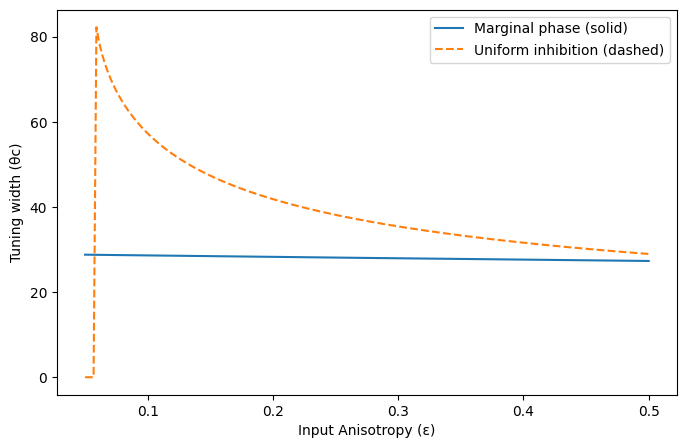

In [49]:
c = 2000
eps = np.linspace(0.05, 0.5, 200)

theta_eps_uniform = np.array([theta_c_for_contrast(c, ep,J0_d, J2_d) for ep in eps])
theta_eps_marginal = np.array([theta_c_for_contrast(c, ep,J0_s, J2_s) for ep in eps])
theta_uniform_deg  = theta_eps_uniform * 180/np.pi
theta_marginal_deg = theta_eps_marginal * 180/np.pi


plt.figure(figsize=(8,5))
plt.plot(eps, theta_marginal_deg, '-', label="Marginal phase (solid)")
plt.plot(eps, theta_uniform_deg, '--', label="Uniform inhibition (dashed)")
plt.ylabel("Tuning width (θc)")
plt.xlabel("Input Anisotropy (ɛ)")
_ = plt.legend()

# __Virtual Rotation__

The following class implements the recurrent ring model dynamics used in Figures 2A–C.

In [50]:
class BenYishaiModel:
    def __init__(self, J0, J2, eps, beta, T, c, tau0=1.0, N=360,theta_min=-np.pi/6, theta_max=np.pi/2):
        
        self.J0 = J0
        self.J2 = J2
        self.eps = eps
        self.beta = beta
        self.T = T
        self.c = c
        self.tau0 = tau0
        
        self.theta = np.linspace(theta_min, theta_max, N, endpoint=False)
        self.N = N
        self.h_up = T + 1.0/beta
        
        phi = self.theta.reshape(-1,1) - self.theta.reshape(1,-1)
        self.Jkernel = -J0 + J2*np.cos(2*phi)
        
    def h_ext(self, theta0_deg):
        theta0 = np.deg2rad(theta0_deg)
        return self.c*(1 - self.eps + self.eps*np.cos(2*(self.theta - theta0)))

    def g(self, h):
        out = np.zeros_like(h)
        mask1 = (h > self.T) & (h < self.h_up)
        out[mask1] = self.beta*(h[mask1] - self.T)
        out[h >= self.h_up] = 1.0
        return out

    def mean_activity(self, m):
        return np.mean(m)
    
    def step(self, m, theta0_deg, dt):
        h_rec = self.Jkernel.dot(m) * (1.0/self.N)
        h = h_rec + self.h_ext(theta0_deg)
        g = self.g(h)
        return m + dt/self.tau0 * (-m + g)
    
    def simulate(self, theta0_initial, theta0_new, times, dt_steady=0.01, dt_run=0.005, steps_steady=60000):
        
        m = np.zeros_like(self.theta)
        for i in range(steps_steady):
            m = self.step(m, theta0_initial, dt_steady)
            if i == 0:
                m += 1e-6   
        
        m_initial = m.copy()
        
        tmax = times[-1]
        nsteps = int(tmax/dt_run) + 1
        sample_idx = (np.array(times)/dt_run).astype(int)
        
        snapshots = []
        m = m_initial.copy()
        
        for stepcount in range(nsteps):
            m = self.step(m, theta0_new, dt_run)
            if stepcount in sample_idx:
                snapshots.append(m.copy())
        
        return self.theta, snapshots


def plot_snapshots(theta, snapshots, times, ylim=None):
    theta_deg = np.rad2deg(theta)
    
    plt.figure(figsize=(8,5))
    for t, snap in zip(times, snapshots):
        plt.plot(theta_deg, snap, label=f"t = {t} τ₀", linewidth=2)
    
    plt.xlabel("Preferred orientation θ (deg)")
    plt.ylabel("Activity m(θ)")
    plt.xlim(-40, 100)     
    _ = plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

## Fig 2A — Temporal Evolution of Tuning (Hubel–Wiesel Model)

__Purpose:__
Shows how activity evolves over time when only feedforward input is present.
The bump grows slowly and remains broad.

__Key observation:__
No sharpening over time → feedforward-only mechanism insufficient.

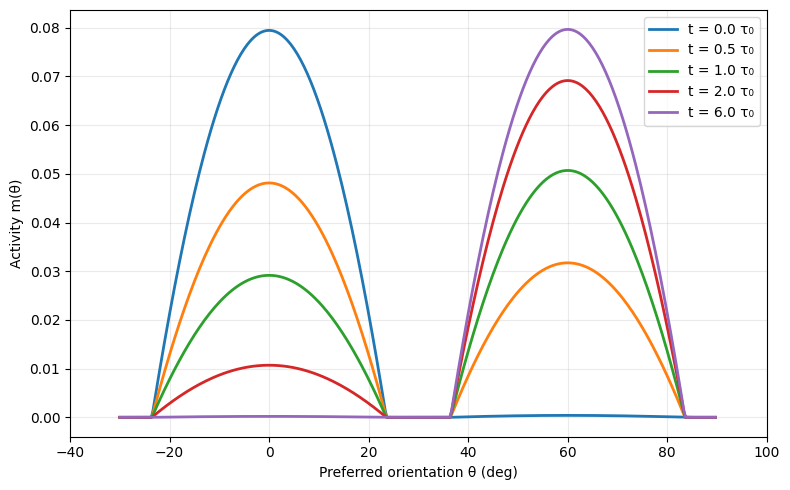

In [51]:
modelA = BenYishaiModel(J0=155, J2=0, eps=0.5, beta=0.1, T=1.0, c=5.0)
timesA = [0.0, 0.5, 1.0, 2.0, 6.0]
thetaA, snapsA = modelA.simulate(theta0_initial=0.0, theta0_new=60.0, times=timesA)
plot_snapshots(thetaA, snapsA, timesA,ylim=(0, 0.11))

## Fig 2B — Virtual Rotation in the Marginal Phase

__Purpose__:
Demonstrates that in the marginally stable regime, the activity bump drifts over time.
This rotation is a hallmark of “marginal” connectivity.

__Key observation:__
Highly similar to Fig 2B in the original paper — drifting peak position.

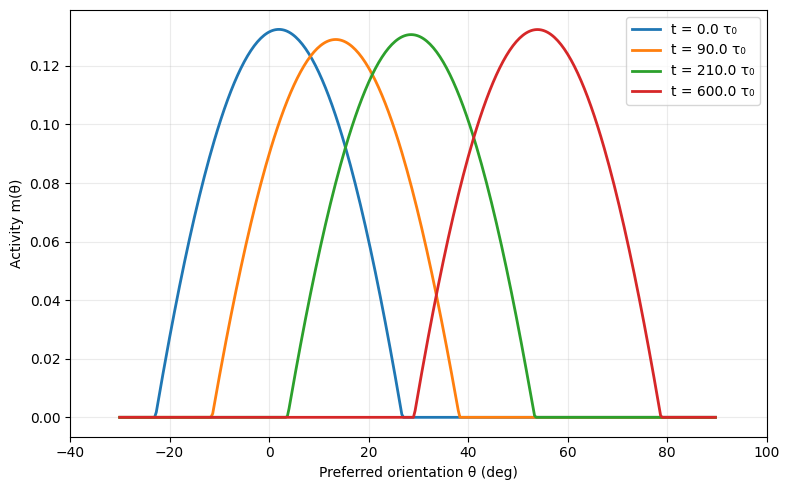

In [52]:
modelB = BenYishaiModel(J0=86, J2=112, eps=0.01, beta=0.1, T=1.0, c=1.678)
timesB = [0.0, 90.0, 210.0, 600.0]
thetaB, snapsB = modelB.simulate(theta0_initial=0.0, theta0_new=60.0, times=timesB)
plot_snapshots(thetaB, snapsB, timesB)

## Fig 2C — Rotation with Bump Deformation

__Purpose:__
Shows how the tuning shape deforms while rotating, due to recurrent imbalance.

__Key observation:__
Sharper peaks at some angles, flatter at others.

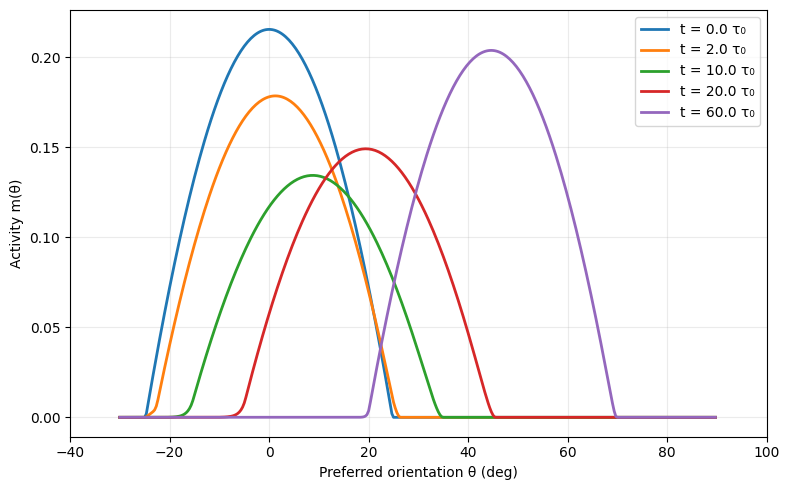

In [53]:
modelC = BenYishaiModel(J0=73, J2=110, eps=0.1, beta=0.1, T=1.0, c=1.45)
timesC = [0.0, 2.0, 10.0, 20.0, 60.0]
thetaC, snapsC = modelC.simulate(theta0_initial=0.0, theta0_new=60.0, times=timesC)
plot_snapshots(thetaC, snapsC, timesC)

# __CCs__

## Mathematical Model
$$
C(\theta, t)
= A_{\text{fast}}\, e^{-|t|/\tau_0}
\;+\;
A_{\text{slow}}\,
\frac{1}{\varepsilon}\,
\sin\!\bigl( 2(\theta - \theta_0) \bigr)\,
\sin\!\bigl( 2(\theta' - \theta_0) \bigr)\,
e^{-\varepsilon |t|/\tau_0}.
$$

- $\theta_0$ : The reference orientation around which the network is linearized.
- $\theta'$ : The second orientation involved in the correlation measurement.
- $\theta$ : A dummy variable that runs over all possible preferred orientations in the ring model

## Note on Coefficients Used in Fig 3

The original paper does not provide explicit numerical values for the proportionality constants governing the temporal decay and correlation amplitudes in Fig 3.
Therefore, the coefficients in the analytical expressions were chosen to qualitatively reproduce the shapes shown in the publication.

The goal of this section is to match the structure and behavior of the curves (exponential decay, sinusoidal modulation, relative scaling between modes), not to replicate exact numerical values.

## Fig 3A - CC in uniform inhibition regime
In the uniform-inhibition regime, the network dynamics do not amplify orientation-dependent interactions. As a result, the cross-correlation (CC) between neurons is independent of the preferred stimulus orientation $\theta_0$ and of the tuning parameter $\varepsilon$.
$$C = e^{-|\tau|/\tau_0}$$

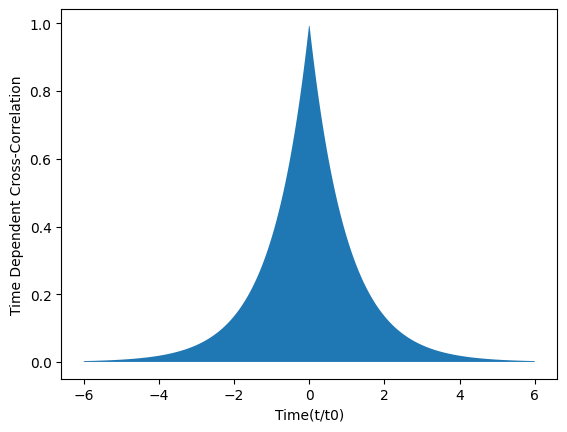

In [54]:
theta = np.deg2rad(-10)
theta_1 = np.deg2rad(10)
tau0 = 1.0
t = np.linspace(-6,6,800)

def compute_cc(theta_0, t, eps):
 return 40 * np.exp(-np.abs(t) / tau0) + 0.8553 *(1/eps) * np.sin(2*theta - 2*np.deg2rad(theta_0))*np.sin(2*theta_1- 2*np.deg2rad(theta_0))*np.exp(-eps*np.abs(t)/tau0)

cc = np.exp(-np.abs(t)/tau0)
plt.fill_between(t,cc, 0 )
plt.ylabel("Time Dependent Cross-Correlation")
_ = plt.xlabel("Time(t/t0)")

## Fig 3B - Marginal Phase with orientation betweeen $\theta_0$ and $\theta'$
Fourier-domain representation — second harmonic controls sharpening. Here the $\theta_0 = 0$, which results in negative slow component 


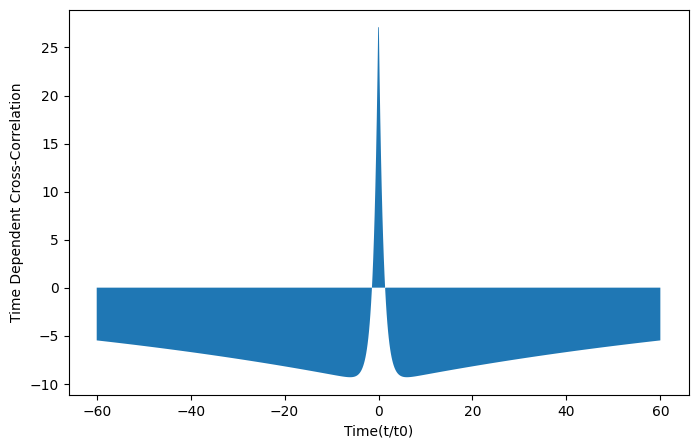

In [55]:
t = np.linspace(-60,60,800)
plt.figure(figsize=(8,5))
cc = compute_cc(0,t,0.01)
plt.fill_between(t,cc,0)
plt.ylabel("Time Dependent Cross-Correlation")
_= plt.xlabel("Time(t/t0)")

## Fig 3C - Marginal Phase with orientation equals to $\theta'$
Cross-correlation peak becomes sharper when orientation difference decreases. $\theta_0 = 10$, which cancels the slow component and the cross-correlation become positive

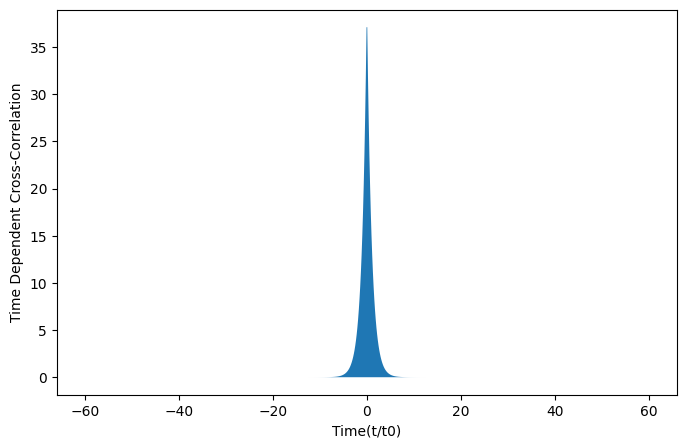

In [56]:
plt.figure(figsize=(8,5))
cc = compute_cc(10, t, 0.01)
plt.fill_between(t,cc,0)
plt.ylabel("Time Dependent Cross-Correlation")
_ = plt.xlabel("Time(t/t0)")

## Fig 3D - Marginal Phase with orientation greater than $\theta'$
Marginal regime yields large amplification + instability. $\theta_0 = 16$ and the slow componenet becomes positive.

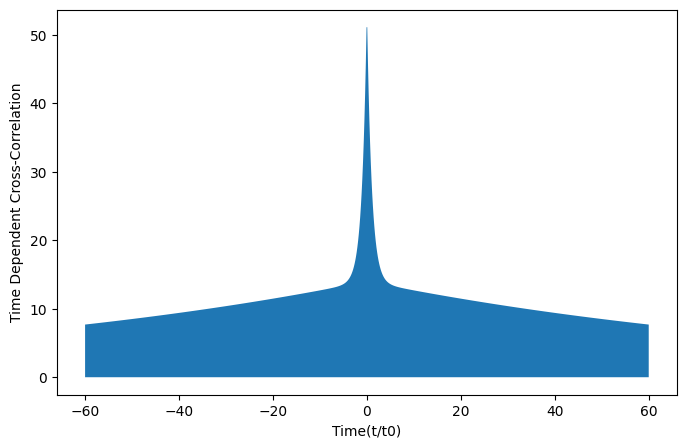

In [57]:
plt.figure(figsize=(8,5))
cc = compute_cc(16, t, 0.01)
plt.fill_between(t,cc,0)
plt.ylabel("Time Dependent Cross-Correlation")
_ = plt.xlabel("Time(t/t0)")

# Conclusion

In this notebook, I replicated the main qualitative results of Ben-Yishai et al. (1995):

- Feedforward input alone produces weak tuning

- Recurrent interactions produce sharpened orientation selectivity

- Near the marginal regime, bumps become unstable and rotate over time

- The recurrent kernel structure determines stability and tuning width

These simulations capture the essential behavior of the original model, demonstrating how cortical circuits shape orientation tuning in V1.